# Connectionist learner: neural network (Keras, JAX)

## Preprocessing

In [1]:
import numpy as np
import polars as pl
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
FEATURES = [
    "length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight",
    "is_infant", "is_female",
]

# cleaning and sex encoding (fixed rules, before the split)
df = pl.read_csv("./data/abalone.csv.zst")
df = df.filter(~((pl.col("height") == 0) | (pl.col("height") > 0.3)))
df = df.with_columns(
    is_infant=(pl.col("sex") == "I").cast(pl.Int8),
    is_female=(pl.col("sex") == "F").cast(pl.Int8),
).drop("sex")

# 20% hold-out test (not used until the end) and 5 stratified folds on the development part
rings_all = df["rings"].to_numpy()
y_bins = np.digitize(rings_all, np.quantile(rings_all, [0.2, 0.4, 0.6, 0.8]))
dev_idx, test_idx = train_test_split(np.arange(df.height), test_size=0.2, random_state=SEED, stratify=y_bins)
dev, test = df[dev_idx], df[test_idx]
X, rings = dev.select(FEATURES).to_numpy(), dev["rings"].to_numpy()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y_bins[dev_idx]))


def cross_validate(fit_predict, verbose=True):
    """fit_predict(X_train, y_train, X_val) -> predictions. Standardization is fitted on each training part."""
    scores = []
    for tr, va in folds:
        scaler = StandardScaler().fit(X[tr])
        pred = fit_predict(scaler.transform(X[tr]), rings[tr], scaler.transform(X[va]))
        scores.append((root_mean_squared_error(rings[va], pred), mean_absolute_error(rings[va], pred), r2_score(rings[va], pred)))
    scores = np.array(scores)
    m, sd = scores.mean(axis=0), scores.std(axis=0, ddof=1)
    if verbose:
        print(f"RMSE {m[0]:.3f} ± {sd[0]:.3f}   MAE {m[1]:.3f} ± {sd[1]:.3f}   R² {m[2]:.3f} ± {sd[2]:.3f}")
    return scores


baseline = cross_validate(lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))

RMSE 3.226 ± 0.159   MAE 2.366 ± 0.084   R² -0.001 ± 0.001


## Model: neural network trained by backpropagation

A multi-layer perceptron in Keras with the JAX backend: 9 inputs, two hidden layers of ReLU units (32 and 16), 1 output.
The weights are learned by gradient descent (Adam) on the mean squared error, with backpropagation.

* `rings` is standardized inside the training part, so the network does not have to learn its mean (about 10).
* L2 penalty on the weights, to keep them small.
* **Early stopping:** 20% of the *training part* is held back, and training stops when the loss on it stops improving. The validation part of the fold is never used for this.

In [2]:
import os

os.environ["KERAS_BACKEND"] = "jax"  # before importing keras
import keras


def mlp(X_tr, y_tr, X_va, units=(32, 16), activation="relu", lr=0.001, l2=1e-4, epochs=200):
    keras.utils.set_random_seed(SEED)
    mu, sd = y_tr.mean(), y_tr.std()
    model = keras.Sequential(
        [keras.layers.Input((X_tr.shape[1],))]
        + [keras.layers.Dense(u, activation=activation, kernel_regularizer=keras.regularizers.l2(l2)) for u in units]
        + [keras.layers.Dense(1)]
    )
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse")
    stop = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)
    model.fit(X_tr, (y_tr - mu) / sd, validation_split=0.2, epochs=epochs, batch_size=64, callbacks=[stop], verbose=0)
    return model.predict(X_va, verbose=0).ravel() * sd + mu


connectionist = cross_validate(mlp)

RMSE 2.107 ± 0.080   MAE 1.513 ± 0.020   R² 0.572 ± 0.026


### Tuning

Hyper-parameters are chosen on the 5 validation folds only. The grid turns out to be flat, so the **simplest** network is preferred (one-standard-error rule): among the configurations whose mean RMSE is within one standard error of the best one (`std / √5` of the best), take the one with the fewest weights, and the lowest mean RMSE if several have the same size.

| Hyper-parameter | Values | Why |
|---|---|---|
| `units` | (16,), (32,), (32, 16), (64, 32) | width and depth of the network, which is its flexibility |
| `activation` | relu, tanh, softplus | the bend of each hidden unit: piecewise linear (relu) or smooth (tanh, softplus) |
| `lr` | 0.001, 0.01 | size of the Adam steps |
| `l2` | 0, 0.001 | penalty on the size of the weights, against overfitting |

Fixed: Adam, MSE loss, batch size 64, up to 200 epochs with early stopping (patience 20) on 20% of the training part. The 4 × 3 × 2 × 2 = 48 combinations are a **grid search**: all of them are tried, and each one is scored with the same 5 folds.

In [3]:
from itertools import product

results = []
for units, activation, lr, l2 in product([(16,), (32,), (32, 16), (64, 32)], ["relu", "tanh", "softplus"], [0.001, 0.01], [0, 0.001]):
    scores = cross_validate(lambda X_tr, y_tr, X_va: mlp(X_tr, y_tr, X_va, units=units, activation=activation, lr=lr, l2=l2), verbose=False)
    sizes = [X.shape[1], *units, 1]
    n_weights = sum(n_in * n_out + n_out for n_in, n_out in zip(sizes, sizes[1:]))
    results.append((str(units), activation, lr, l2, n_weights, scores[:, 0].mean(), scores[:, 0].std(ddof=1)))

tuning = pl.DataFrame(results, schema=["units", "activation", "lr", "l2", "weights", "mean RMSE", "std RMSE"], orient="row").sort("mean RMSE")

with pl.Config(tbl_rows=10):
    print(tuning)
top = tuning.row(0, named=True)
limit = top["mean RMSE"] + top["std RMSE"] / np.sqrt(len(folds))
best = tuning.filter(pl.col("mean RMSE") <= limit).sort(["weights", "mean RMSE"]).row(0, named=True)
print("lowest mean RMSE:", {k: top[k] for k in ['units', 'activation', 'lr', 'l2', 'weights']}, f"RMSE {top['mean RMSE']:.3f}")
print("simplest within one standard error:", {k: best[k] for k in ['units', 'activation', 'lr', 'l2', 'weights']}, f"RMSE {best['mean RMSE']:.3f}, limit {limit:.3f}")

shape: (48, 7)
┌──────────┬────────────┬───────┬───────┬─────────┬───────────┬──────────┐
│ units    ┆ activation ┆ lr    ┆ l2    ┆ weights ┆ mean RMSE ┆ std RMSE │
│ ---      ┆ ---        ┆ ---   ┆ ---   ┆ ---     ┆ ---       ┆ ---      │
│ str      ┆ str        ┆ f64   ┆ f64   ┆ i64     ┆ f64       ┆ f64      │
╞══════════╪════════════╪═══════╪═══════╪═════════╪═══════════╪══════════╡
│ (32, 16) ┆ tanh       ┆ 0.01  ┆ 0.001 ┆ 865     ┆ 2.061298  ┆ 0.068458 │
│ (64, 32) ┆ tanh       ┆ 0.001 ┆ 0.001 ┆ 2753    ┆ 2.063113  ┆ 0.065845 │
│ (64, 32) ┆ tanh       ┆ 0.01  ┆ 0.001 ┆ 2753    ┆ 2.070615  ┆ 0.066923 │
│ (64, 32) ┆ tanh       ┆ 0.01  ┆ 0.0   ┆ 2753    ┆ 2.076353  ┆ 0.072792 │
│ (64, 32) ┆ relu       ┆ 0.001 ┆ 0.001 ┆ 2753    ┆ 2.078419  ┆ 0.067122 │
│ …        ┆ …          ┆ …     ┆ …     ┆ …       ┆ …         ┆ …        │
│ (32,)    ┆ softplus   ┆ 0.001 ┆ 0.0   ┆ 353     ┆ 2.120967  ┆ 0.082501 │
│ (64, 32) ┆ softplus   ┆ 0.01  ┆ 0.0   ┆ 2753    ┆ 2.122821  ┆ 0.071287 │
│ (32,)   

## Final evaluation on the test set

The chosen hyper-parameters (simplest within one standard error of the best) are used to refit the model on the **whole development part** (3338 rows), and the model is scored **once** on the 20% test set (835 rows). Nothing is chosen from the test result.

baseline   test RMSE 3.207   MAE 2.351   R² -0.000


Keras MLP  test RMSE 2.145   MAE 1.510   R² 0.552


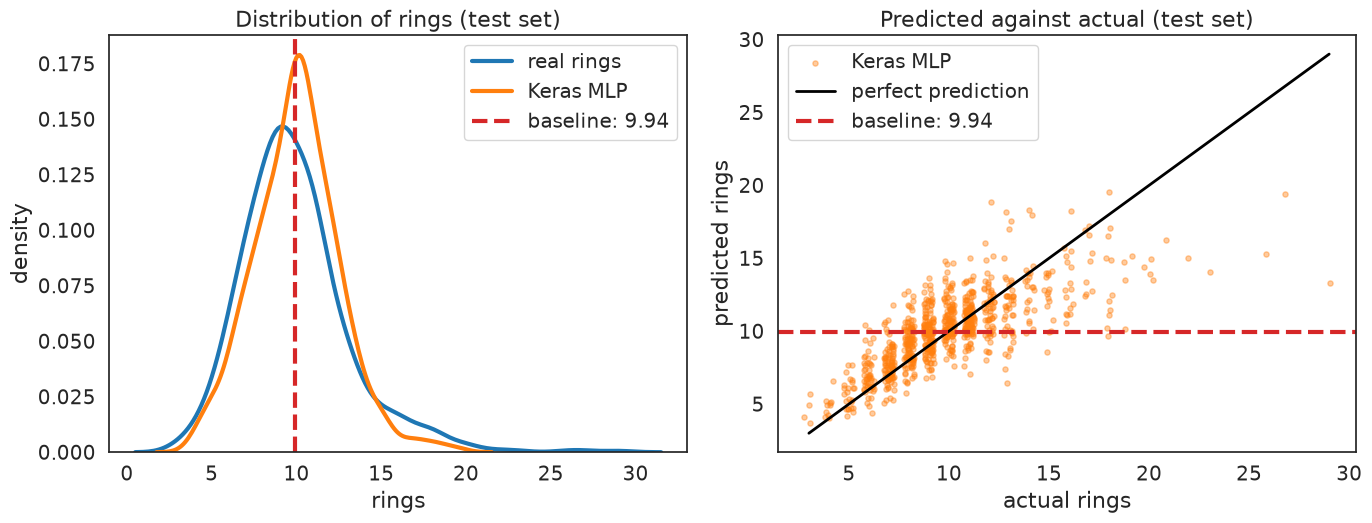

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import ast

def test_evaluate(name, fit_predict):
    """Refit on the whole development part (standardized with its own mean and sd) and score once on the test set."""
    scaler = StandardScaler().fit(X)
    y = test["rings"].to_numpy()
    pred = fit_predict(scaler.transform(X), rings, scaler.transform(test.select(FEATURES).to_numpy()))
    print(f"{name:10s} test RMSE {root_mean_squared_error(y, pred):.3f}   MAE {mean_absolute_error(y, pred):.3f}   R² {r2_score(y, pred):.3f}")
    return pred


def plot_test(pred, name):
    """Left: distribution of the real rings, of the predictions and of the baseline. Right: predicted against actual."""
    y_test, base = test["rings"].to_numpy(), rings.mean()
    jitter = np.random.default_rng(SEED).uniform(-0.25, 0.25, len(y_test))  # rings are integers: spread the dots sideways
    with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.3):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
        sns.kdeplot(y_test, ax=ax1, lw=3, color="C0", label="real rings")
        sns.kdeplot(pred, ax=ax1, lw=3, color="C1", label=name)
        ax1.axvline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax1.set(title="Distribution of rings (test set)", xlabel="rings", ylabel="density")
        ax1.legend()
        ax2.scatter(y_test + jitter, pred, s=14, alpha=0.4, color="C1", label=name)
        ax2.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="k", lw=2, label="perfect prediction")
        ax2.axhline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax2.set(title="Predicted against actual (test set)", xlabel="actual rings", ylabel="predicted rings")
        ax2.legend()
        plt.tight_layout()
        plt.show()


test_evaluate("baseline", lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))
final = lambda X_tr, y_tr, X_va: mlp(X_tr, y_tr, X_va, units=ast.literal_eval(best["units"]), activation=best["activation"], lr=best["lr"], l2=best["l2"])
pred = test_evaluate("Keras MLP", final)
plot_test(pred, "Keras MLP")

# validation scores of the chosen model and its test predictions, for the comparison in evaluation.ipynb
val = cross_validate(final, verbose=False)
Path("results").mkdir(exist_ok=True)
np.savez("results/connectionists.npz", val_rmse=val[:, 0], baseline_rmse=baseline[:, 0], test_y=test["rings"].to_numpy(), test_pred=pred)